In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
df = pd.read_csv("train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [ ]:
X = df.drop(
    columns=['Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin']
)

y = df['Survived']

numerical_cols = ['Age', 'SibSp', 'Parch', 'Fare']

categorical_cols = ['Pclass', 'Sex', 'Embarked']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (712, 7)
Testing Data: (179, 7)


In [ ]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [ ]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [ ]:
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_cols),
    ('cat', categorical_pipeline, categorical_cols)
])

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training Data After Preprocessing:", X_train_processed.shape)

print("Testing Data After Preprocessing:", X_test_processed.shape)

Training Data After Preprocessing: (712, 12)
Testing Data After Preprocessing: (179, 12)


In [ ]:
model = LogisticRegression(max_iter=1000)

In [ ]:
model.fit(X_train_processed, y_train)

print("Model Training Completed!")

Model Training Completed!


In [ ]:
y_pred = model.predict(X_test_processed)

print("Predicted Values:")
print(y_pred)

Predicted Values:
[0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0
 0 0 1 0 1 0 1 1 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 1 0 0 0 1 1 0 0 0 1 0 1 1
 0 0 0 0 0 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 0 0 0
 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0
 1 1 0 0 1 1 0 1 0 0 0 1 1 1 1 1 1 1 0 0 1 1 0 0 1 0 1 0 0 1 0]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 80.45 %


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[98 12]
 [23 46]]


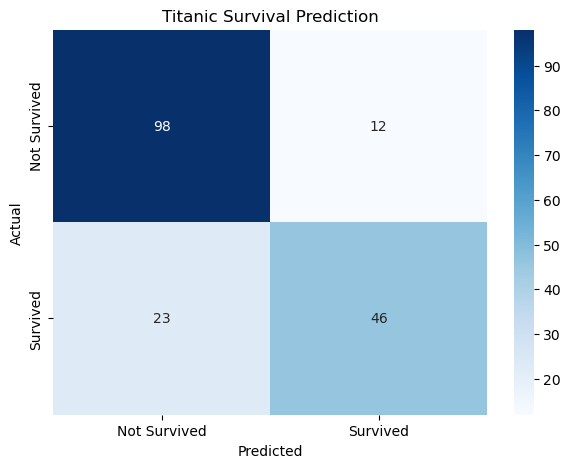

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title("Titanic Survival Prediction")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

results.to_csv("titanic_predictions.csv", index=False)

print("Predictions saved successfully!")

Predictions saved successfully!


In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

print("SCALED NUMERICAL DATA:")
print(X_train_processed[:, :len(numerical_cols)])

print("\nENCODED CATEGORICAL DATA:")
print(preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(categorical_cols))

print("\nCOMPLETE PREPROCESSED TRAINING DATA:")
print(X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed)

print("\nCOMPLETE PREPROCESSED TESTING DATA:")
print(X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed)

SCALED NUMERICAL DATA:
[[-0.08113533 -0.46508428 -0.46618317  0.5138115 ]
 [-0.08113533 -0.46508428 -0.46618317 -0.66256323]
 [-0.08113533 -0.46508428 -0.46618317  3.95539858]
 ...
 [ 1.41700669  0.47833454  3.11571343  0.0532047 ]
 [ 1.34017889 -0.46508428 -0.46618317  0.13909685]
 [-0.08113533 -0.46508428 -0.46618317 -0.10973011]]

ENCODED CATEGORICAL DATA:
['Pclass_1' 'Pclass_2' 'Pclass_3' 'Sex_female' 'Sex_male' 'Embarked_C'
 'Embarked_Q' 'Embarked_S']

COMPLETE PREPROCESSED TRAINING DATA:
[[-0.08113533 -0.46508428 -0.46618317 ...  0.          0.
   1.        ]
 [-0.08113533 -0.46508428 -0.46618317 ...  0.          0.
   1.        ]
 [-0.08113533 -0.46508428 -0.46618317 ...  0.          0.
   1.        ]
 ...
 [ 1.41700669  0.47833454  3.11571343 ...  0.          0.
   1.        ]
 [ 1.34017889 -0.46508428 -0.46618317 ...  0.          0.
   1.        ]
 [-0.08113533 -0.46508428 -0.46618317 ...  0.          0.
   1.        ]]

COMPLETE PREPROCESSED TESTING DATA:
[[-0.42686041  1.421